# Reading a SHIFT market-maker run

Post-run analysis of one 60-minute SHIFT session of the Avellaneda-Stoikov
market maker in `market_maker.py`, across five equities (AAPL, AMZN, BRKb, GOOG,
MSFT). The bot logs every market snapshot, quote, order and fill into a
multi-tab Excel report; this notebook reads that report back.

**What this run shows and doesn't.** The SHIFT account this session traded on
already carried positions and realized P&L from earlier testing before this
session; the numbers below separate that pre-existing tests
from what this specific session actually did. The feed was also nearly static
over the hour, so volatility mostly sat at its floor and the bot took only two
fills; this is a demonstration of the quoting and inventory-control machinery,
not a P&L result.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "font.size": 11})

# Use the newest run report in data/
REPORT = sorted(Path("data").glob("shift_run_report_*.xlsx"))[-1]
print("reading", REPORT.name)

xls = pd.ExcelFile(REPORT)
run_info  = pd.read_excel(xls, "RunInfo")
market    = pd.read_excel(xls, "Market")
quotes    = pd.read_excel(xls, "Quotes")
fills     = pd.read_excel(xls, "Fills")

for df in (market, quotes, fills):
    if "ts" in df.columns:
        df["ts"] = pd.to_datetime(df["ts"])

SYMBOLS = sorted(market["symbol"].unique())
run_info

reading shift_run_report_20251214_170837.xlsx


,key,value
0,start_utc,2025-12-14 16:08:29.267
1,end_utc,2025-12-14 17:08:37.874
2,duration_min,60.143446
3,symbols,"AAPL, AMZN, BRKb, GOOG, MSFT"


## Run summary

The report's own `Summary` tab leaves `fills_count`, `avg_buy_px` and similar
columns blank: they're Excel formulas that `openpyxl` writes as text but never
evaluates (nothing has opened this file in a real spreadsheet app to calculate
them). Recomputed here directly from the `Fills` and `Market` tabs instead.

More importantly: `initial_realized_pl` is **not this session's result**. A
SHIFT account persists across runs the same way a real brokerage account does,
so whatever P&L and positions existed on this account *before* this session
started are still sitting there when it begins. `session_pl` (ending minus
starting) is the number that actually reflects this run.

In [2]:
ending_pl = (
    market.sort_values("ts")
    .groupby("symbol")["realized_pl"]
    .last()
    .rename("ending_realized_pl")
)
starting_pl = (
    market.sort_values("ts")
    .groupby("symbol")["realized_pl"]
    .first()
    .rename("starting_realized_pl")
)
max_abs_shares = market.groupby("symbol")["shares"].apply(lambda s: s.abs().max()).rename("max_abs_shares")
fills_count = fills.groupby("symbol").size().rename("fills_count")

summary = (
    pd.concat([starting_pl, ending_pl, max_abs_shares, fills_count], axis=1)
    .fillna({"fills_count": 0})
    .astype({"fills_count": int})
)
summary["session_pl"] = summary["ending_realized_pl"] - summary["starting_realized_pl"]
summary = summary.reset_index().rename(columns={"index": "symbol"})
summary

,symbol,starting_realized_pl,ending_realized_pl,max_abs_shares,fills_count,session_pl
0,AAPL,-309.0,-309.0,0,0,0.0
1,AMZN,-312.0,-312.0,0,0,0.0
2,BRKb,-565.0,-565.0,300,0,0.0
3,GOOG,79.0,79.0,0,0,0.0
4,MSFT,-197.0,-181.0,100,2,16.0


Every symbol's `starting_realized_pl` is a large pre-existing number from
before this session; `session_pl` is tiny by comparison because almost nothing
traded. The only nonzero `session_pl` belongs to MSFT, the only symbol with any
fills this run.

## The only fills in this run

In [3]:
print(f"{len(fills)} fills in this run, out of {len(quotes)} quotes logged "
      f"({len(fills) / len(quotes):.2%} of quotes led to a fill)")
fills

2 fills in this run, out of 4428 quotes logged (0.05% of quotes led to a fill)


,ts,symbol,side,lots,shares,price,order_id,order_type,mid_at_fill,slippage_to_mid,cashflow,sigma,quoted_bid,quoted_ask
0,2025-12-14 11:08:31.047953,MSFT,BUY,1,100,108.15,7aa83410-c4b0-464e-9b53-c5550d2f29bf,Type.MARKET_BUY,108.145,0.005,-10815,0.0002,NaN,NaN
1,2025-12-14 12:07:30.295398,MSFT,SELL,1,100,108.31,2b99e4d2-c3ca-4955-a7d0-6e2db010df36,Type.MARKET_SELL,108.315,-0.005,10831,0.0002,108.3,108.31


Two fills: MSFT bought at 108.15, sold at 108.31 a little under an hour later.
`cashflow` sums to exactly `session_pl` for MSFT above (a $16 realized gain on
that one round trip). The two numbers agreeing is itself a useful sanity
check that the P&L bookkeeping is internally consistent.

**4,428 quotes against 2 fills.** In a market this quiet,
the overwhelming majority of resting limit orders just get cancelled and
replaced on the next cycle without anyone trading against them. It's more
evidence that this run demonstrates the quoting mechanics, not performance.

## Inventory over time

Inventory in shares, per symbol, straight from the `Market` log. Three of the
five never leave flat; `BRKb` carries ~300 shares for the *entire* run;
checking the Market log confirms that position was already there at the very
first logged moment, before the bot could have placed an order, so it's
inherited account state, not something this session built up. `MSFT` is the
only symbol whose inventory actually moves (0 to 100 shares and back, the one
round trip above).

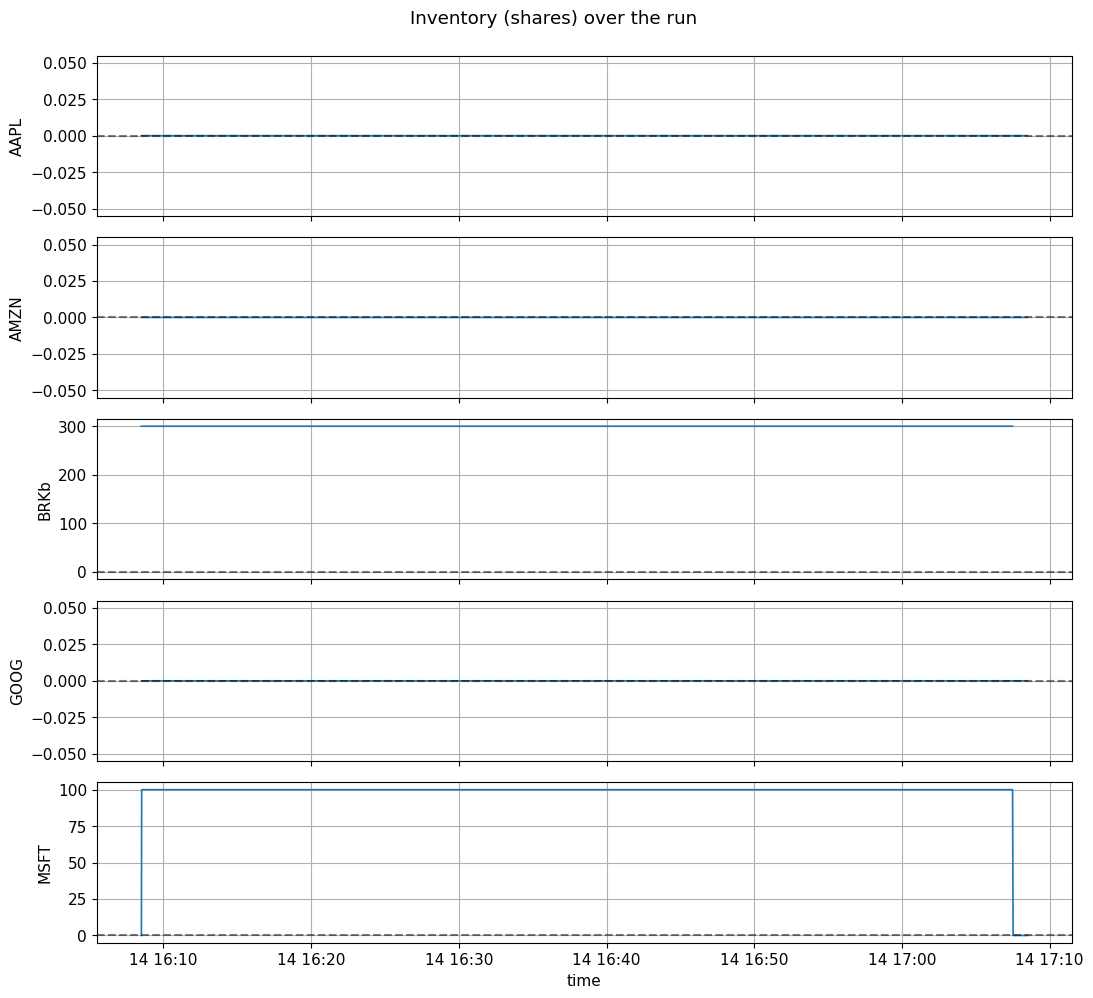

In [4]:
fig, axes = plt.subplots(len(SYMBOLS), 1, figsize=(11, 2.0 * len(SYMBOLS)), sharex=True)
for ax, sym in zip(axes, SYMBOLS):
    d = market[market["symbol"] == sym]
    ax.plot(d["ts"], d["shares"], linewidth=1.2)
    ax.axhline(0, linestyle="--", color="black", alpha=0.5)
    ax.set_ylabel(sym)
axes[-1].set_xlabel("time")
fig.suptitle("Inventory (shares) over the run", y=0.995)
fig.tight_layout()
plt.show()

## Avellaneda-Stoikov mechanics: what this run can and can't show

The model's two signature behaviours:

1. **Reservation price skews with inventory** (`r = mid - q*gamma*sigma^2*T`) but
   needs inventory to actually *change* to see a slope.
2. **Spread widens with volatility** but needs `sigma` to actually move.

Checked directly against this run's `Quotes` log: `inv_lots` is **constant**
for every symbol except MSFT's single 0-to-1-lot round trip (BRKb sits at
exactly 3 lots for literally every quote it made).

`sigma` *does* move for BRKb (0.0002 to 0.0050 over the run), so the
spread-vs-sigma relationship is the one AS mechanic this run has
evidence for:

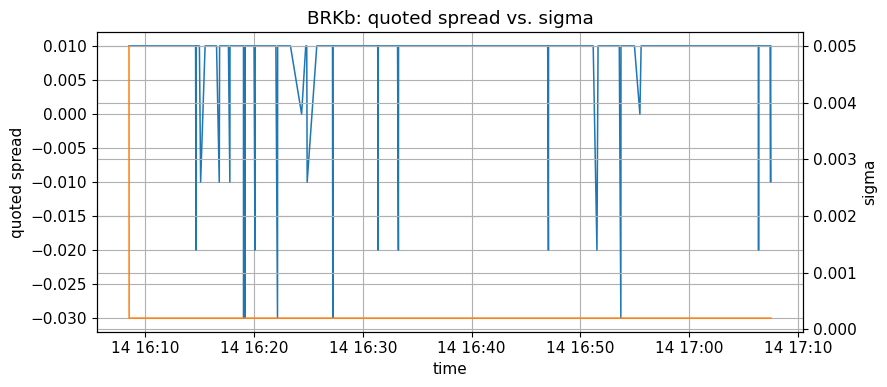

In [5]:
b = quotes[quotes["symbol"] == "BRKb"].copy()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(b["ts"], b["quoted_spread"], label="quoted spread", linewidth=1.1)
ax.set_ylabel("quoted spread")
ax2 = ax.twinx()
ax2.plot(b["ts"], b["sigma"], color="tab:orange", linewidth=1.1, label="sigma")
ax2.set_ylabel("sigma")
ax.set_title("BRKb: quoted spread vs. sigma")
ax.set_xlabel("time")
fig.tight_layout()
plt.show()

## Quoting cadence

How often the bot requoted, and why (`reason` is `NORMAL` vs `FORCED`
liquidation), per symbol.

In [6]:
cadence = (
    quotes.groupby(["symbol", "reason"]).size().unstack(fill_value=0)
    .assign(total=lambda d: d.sum(axis=1))
)
cadence

reason,FORCED,NORMAL,total
symbol,,,
AAPL,45,680,725
AMZN,95,1790,1885
BRKb,19,381,400
GOOG,36,993,1029
MSFT,21,368,389


## Takeaway

First separating what this session actually did from what the account already
carried. The `starting_realized_pl` numbers look
large and mostly negative, but that's inherited baggage from earlier testing on
this SHIFT account, not this run's result; this session itself only ever
touched MSFT, earning a real (if tiny) $16 on one round trip. BRKb's 300-share
position sat completely unchanged the entire hour; present before the first
logged tick, never traded, so it can't demonstrate the reservation-price /
inventory skew the model predicts. What the run *does* show cleanly:
inventory stays bounded, the one symbol with real volatility (BRKb) widens its
spread when sigma rises, and with 4,428 quotes against 2 fills, this is a
mechanics demonstration, not a trading result. A run against a livelier SHIFT
session with more fills, more inventory actually moving, is a natural next
step.